In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
df = pd.read_csv("cleaned_ecommerce_data.csv")

In [11]:
df.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


In [13]:
X = df[[
    "Age",
    "Quantity",
    "Unit_Price",
    "Discount_Amount",
    "Customer_Rating"
]]

y = df["Total_Amount"]
X.head()

,Age,Quantity,Unit_Price,Discount_Amount,Customer_Rating
0,40,1,29.18,0.00,4
1,40,1,644.40,138.05,2
2,40,5,332.82,0.00,4
3,33,5,69.30,71.05,4
4,33,3,178.15,0.00,4


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
X_train.shape

(480, 5)

In [16]:
model = LinearRegression()

In [17]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 5.56,337.1 , 2.81, 0.72,-17.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Age','Quantity','Unit_Price','Discount_Amount','Customer_Rating']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1191
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [18]:
y_pred = model.predict(X_test)

In [19]:
y_pred[:10]

array([3403.79968792,  600.1268574 ,  385.14085505,  382.16229657,
        594.57552516, 1189.9066191 ,  739.91923414,  131.69561864,
       -113.58005564, 2438.03367818])

In [20]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

MAE : 377.22954114857913
MSE : 461640.3126064965
R2 Score : 0.750173566725911


In [21]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results.head()

,Actual,Predicted
110,2781.66,3403.799688
419,548.08,600.126857
565,330.89,385.140855
77,156.08,382.162297
181,732.09,594.575525


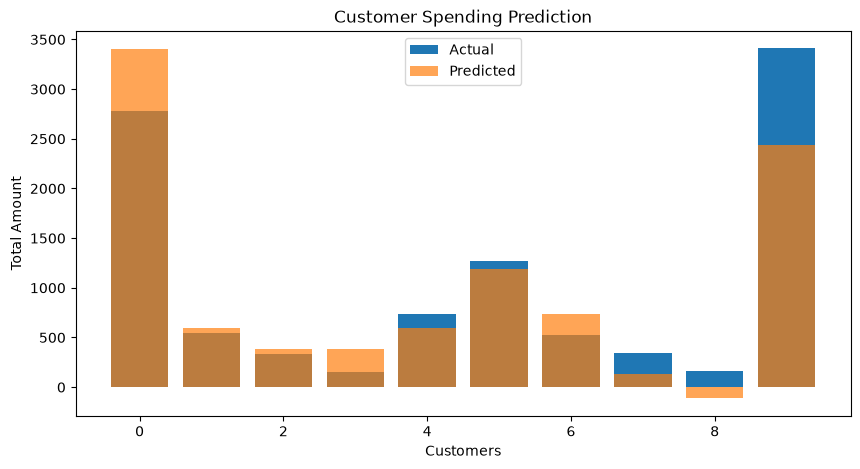

In [22]:
plt.figure(figsize=(10,5))

plt.bar(range(len(results.head(10))),
        results["Actual"].head(10),
        label="Actual")

plt.bar(range(len(results.head(10))),
        results["Predicted"].head(10),
        alpha=0.7,
        label="Predicted")

plt.title("Customer Spending Prediction")
plt.xlabel("Customers")
plt.ylabel("Total Amount")
plt.legend()

plt.show()

In [23]:
results.to_csv("customer_spending_prediction.csv", index=False)

In [25]:
results.to_csv("customer_spending_prediction.csv", index=False)

In [26]:
results.head()

,Actual,Predicted
110,2781.66,3403.799688
419,548.08,600.126857
565,330.89,385.140855
77,156.08,382.162297
181,732.09,594.575525


In [27]:
results.to_csv("customer_spending_prediction.csv", index=False)